# Consigna 1 — Regresión temporal del consumo de electrodomésticos

**Práctica de selección de variables con redes neuronales (IA — Semana 6)**
Autor: Barreto

**Objetivo.** Explorar las variables ambientales y temporales del dataset *Appliances Energy Prediction* (UCI, id 374), proponer subconjuntos de variables informativos y comparar una RNA (`MLPRegressor`) entrenada con todas las variables contra **la misma arquitectura** entrenada con el subconjunto elegido.

**Reglas del experimento** (criterio común de la consigna):
- Lo único que cambia entre corridas es el conjunto de variables. Arquitectura, particiones, semilla, preprocesamiento y métricas quedan fijos.
- Toda la selección de variables (rankings, Lasso, umbrales) se calcula **solo con entrenamiento**; validación se usa para comparar subconjuntos.
- La partición respeta el orden temporal (70 % / 15 % / 15 %) y el conjunto de **prueba se evalúa una única vez**, al final.

In [1]:
# %pip install ucimlrepo   # descomentar si no está instalado

import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy.cluster import hierarchy
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from ucimlrepo import fetch_ucirepo

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.precision", 3)
SEED = 42

## 1. Descarga, orden temporal y descripción de las variables

> **Nota sobre el código inicial.** En la versión actual de `ucimlrepo` la columna `date` llega como texto **sin espacio** entre fecha y hora (`"2016-01-1117:00:00"`), por lo que `pd.to_datetime(df["date"])` sin formato lanza `DateParseError`. Se indica el formato explícito `"%Y-%m-%d%H:%M:%S"`; el resto del código inicial se mantiene.

In [2]:
energy = fetch_ucirepo(id=374)

X_raw = energy.data.features.copy()
y_raw = energy.data.targets.squeeze().astype(float)

df = X_raw.copy()
df["Appliances"] = y_raw.to_numpy()
print("Ejemplo de fecha cruda:", repr(df["date"].iloc[0]))
df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d%H:%M:%S")
df = df.sort_values("date").reset_index(drop=True)

print(df.shape, "| desde", df["date"].min(), "hasta", df["date"].max())
print("Faltantes totales:", int(df.isna().sum().sum()))
print("Paso temporal más frecuente:", df["date"].diff().mode()[0])

Ejemplo de fecha cruda: '2016-01-1117:00:00'
(19735, 29) | desde 2016-01-11 17:00:00 hasta 2016-05-27 18:00:00
Faltantes totales: 0
Paso temporal más frecuente: 0 days 00:10:00


Diccionario resumido de variables (según la ficha de UCI):

| Grupo | Variables | Descripción |
|---|---|---|
| Objetivo | `Appliances` | Energía de electrodomésticos en el intervalo de 10 min (Wh) |
| Consumo | `lights` | Energía de iluminación en el mismo intervalo (Wh) |
| Interior | `T1…T9`, `RH_1…RH_9` | Temperatura (°C) y humedad relativa (%) por ambiente: 1 cocina, 2 living, 3 lavadero, 4 oficina, 5 baño, 6 **exterior norte**, 7 planchado, 8 dormitorio adolescente, 9 padres |
| Estación meteorológica | `T_out`, `Press_mm_hg`, `RH_out`, `Windspeed`, `Visibility`, `Tdewpoint` | Clima del aeropuerto de Chièvres, interpolado a 10 min |
| Control | `rv1`, `rv2` | Variables **aleatorias** agregadas a propósito por los autores para testear métodos de selección |

In [3]:
display(df.describe().T[["mean", "std", "min", "50%", "max"]])

,mean,std,min,50%,max
date,2016-03-20 05:29:59.999999,NaN,2016-01-11 17:00:00,2016-03-20 05:30:00,2016-05-27 18:00:00
lights,3.802,7.936,0.0,0.0,70.0
T1,21.687,1.606,16.79,21.6,26.26
RH_1,40.26,3.979,27.023,39.657,63.36
T2,20.341,2.193,16.1,20.0,29.857
RH_2,40.42,4.07,20.463,40.5,56.027
T3,22.268,2.006,17.2,22.1,29.236
RH_3,39.243,3.255,28.767,38.53,50.163
T4,20.855,2.043,15.1,20.667,26.2
RH_4,39.027,4.341,27.66,38.4,51.09


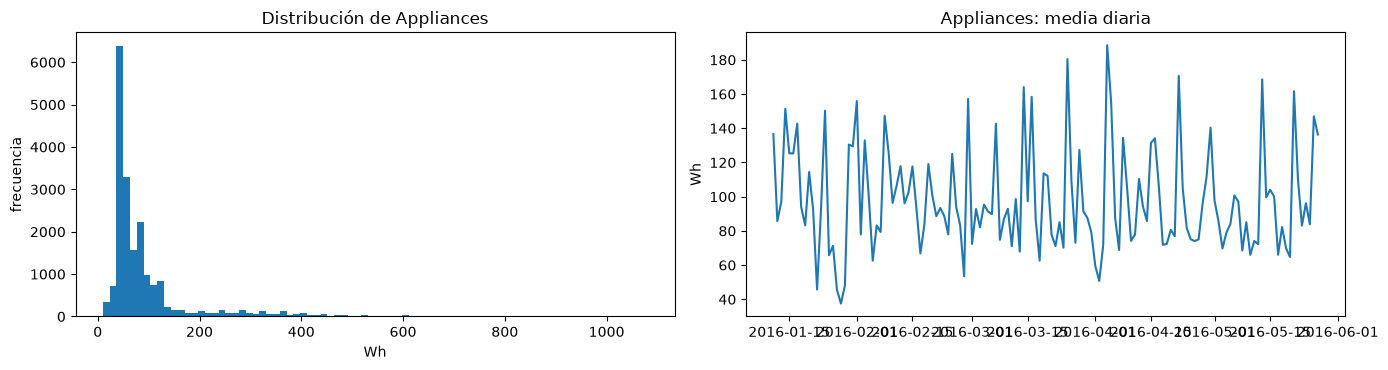

Asimetría: 3.39 | mediana: 60.0 | p95: 330.0


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist(df["Appliances"], bins=80, color="tab:blue")
axes[0].set(title="Distribución de Appliances", xlabel="Wh", ylabel="frecuencia")
diario = df.set_index("date")["Appliances"].resample("D").mean()
axes[1].plot(diario.index, diario.values)
axes[1].set(title="Appliances: media diaria", ylabel="Wh")
plt.tight_layout(); plt.show()

print("Asimetría:", round(df["Appliances"].skew(), 2),
      "| mediana:", df["Appliances"].median(), "| p95:", df["Appliances"].quantile(.95))

El objetivo es muy **asimétrico**: la mediana es 60 Wh pero hay picos de hasta 1080 Wh. La mayor parte del error de cualquier modelo va a venir de esos picos, que son eventos cortos (horno, lavarropas) difíciles de anticipar con variables ambientales.

## 2. Atributos temporales

La fecha no entra como texto. Se codifica la hora en forma **cíclica** (seno/coseno, para que 23 h y 0 h queden cerca) y el día de la semana, tal como propone el código inicial.

In [5]:
df["hour_sin"] = np.sin(2 * np.pi * df["date"].dt.hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["date"].dt.hour / 24)
df["day_of_week"] = df["date"].dt.dayofweek

fechas = df["date"].copy()
y = df.pop("Appliances")
X = df.drop(columns="date")

print(X.shape)
display(X.head())

(19735, 30)


,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,...,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,hour_sin,hour_cos,day_of_week
0,30,19.89,47.597,19.2,44.790,19.79,44.730,19.000,45.567,17.167,...,733.5,92.0,7.000,63.000,5.3,13.275,13.275,-0.966,-0.259,0
1,30,19.89,46.693,19.2,44.722,19.79,44.790,19.000,45.992,17.167,...,733.6,92.0,6.667,59.167,5.2,18.606,18.606,-0.966,-0.259,0
2,30,19.89,46.300,19.2,44.627,19.79,44.933,18.927,45.890,17.167,...,733.7,92.0,6.333,55.333,5.1,28.643,28.643,-0.966,-0.259,0
3,40,19.89,46.067,19.2,44.590,19.79,45.000,18.890,45.723,17.167,...,733.8,92.0,6.000,51.500,5.0,45.410,45.410,-0.966,-0.259,0
4,40,19.89,46.333,19.2,44.530,19.79,45.000,18.890,45.530,17.200,...,733.9,92.0,5.667,47.667,4.9,10.084,10.084,-0.966,-0.259,0


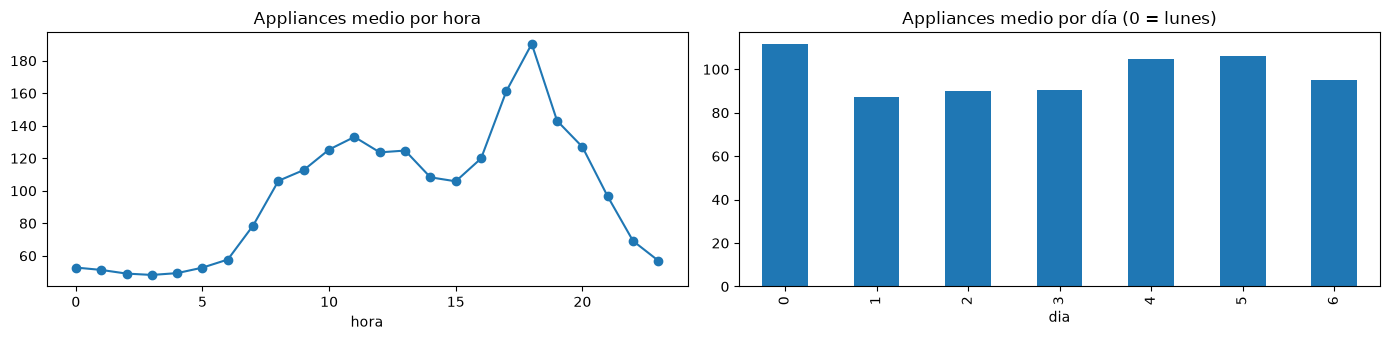

In [6]:
perfil = pd.DataFrame({"hora": fechas.dt.hour, "dia": fechas.dt.dayofweek, "y": y})
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
perfil.groupby("hora")["y"].mean().plot(ax=axes[0], marker="o", title="Appliances medio por hora")
perfil.groupby("dia")["y"].mean().plot(ax=axes[1], kind="bar", title="Appliances medio por día (0 = lunes)")
plt.tight_layout(); plt.show()

Hay un patrón horario marcado (mínimo de madrugada, picos a la mañana y a las 17–19 h), por eso se espera que `hour_sin`/`hour_cos` sean relevantes. El efecto del día de la semana es más débil.

## 3. Partición cronológica

Se separa **antes** de explorar asociaciones, para que todos los rankings usen solo entrenamiento.

In [7]:
n = len(X)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

X_train, y_train = X.iloc[:fin_train], y.iloc[:fin_train]
X_val, y_val = X.iloc[fin_train:fin_val], y.iloc[fin_train:fin_val]
X_test, y_test = X.iloc[fin_val:], y.iloc[fin_val:]

for nombre, idx in [("train", slice(0, fin_train)), ("val", slice(fin_train, fin_val)), ("test", slice(fin_val, n))]:
    f = fechas.iloc[idx]
    print(f"{nombre:5s} {len(f):6d} registros  {f.min():%Y-%m-%d} → {f.max():%Y-%m-%d}")

train  13814 registros  2016-01-11 → 2016-04-16
val     2960 registros  2016-04-16 → 2016-05-07
test    2961 registros  2016-05-07 → 2016-05-27


Entrenamiento cubre enero–mediados de abril (invierno), mientras que validación y prueba caen en abril–mayo (primavera). Esto va a ser importante para interpretar los resultados.

## 4. Exploración: asociaciones, redundancias y `rv1`/`rv2`

### 4.1 Asociación con el objetivo (solo train)

Se usa correlación de **Spearman** (robusta a la asimetría de `Appliances`) y se guarda también Pearson para comparar.

In [8]:
asoc = pd.DataFrame({
    "spearman": X_train.corrwith(y_train, method="spearman"),
    "pearson": X_train.corrwith(y_train),
}).sort_values("spearman", key=abs, ascending=False)
display(asoc.T)

,hour_sin,lights,T2,hour_cos,T1,T8,T4,T3,RH_8,RH_out,...,Windspeed,RH_1,Tdewpoint,RH_5,RH_3,RH_4,day_of_week,Visibility,rv1,rv2
spearman,-0.431,0.354,0.325,-0.297,0.265,0.258,0.240,0.239,-0.235,-0.220,...,0.083,0.072,0.061,-0.056,-0.048,-0.026,-0.013,-0.012,-0.008,-0.008
pearson,-0.250,0.226,0.150,-0.226,0.084,0.072,0.077,0.121,-0.116,-0.147,...,0.066,0.089,0.010,-0.002,0.033,-0.003,-0.046,-0.008,-0.009,-0.009


Las asociaciones son **débiles** en general (|ρ| < 0.45). Las más fuertes son la hora (`hour_sin`, `hour_cos`), `lights` y las temperaturas interiores (`T2`, `T1`, `T8`, `T3`…). `rv1` y `rv2` tienen correlación prácticamente nula, como se espera de ruido.

### 4.2 Redundancia entre sensores

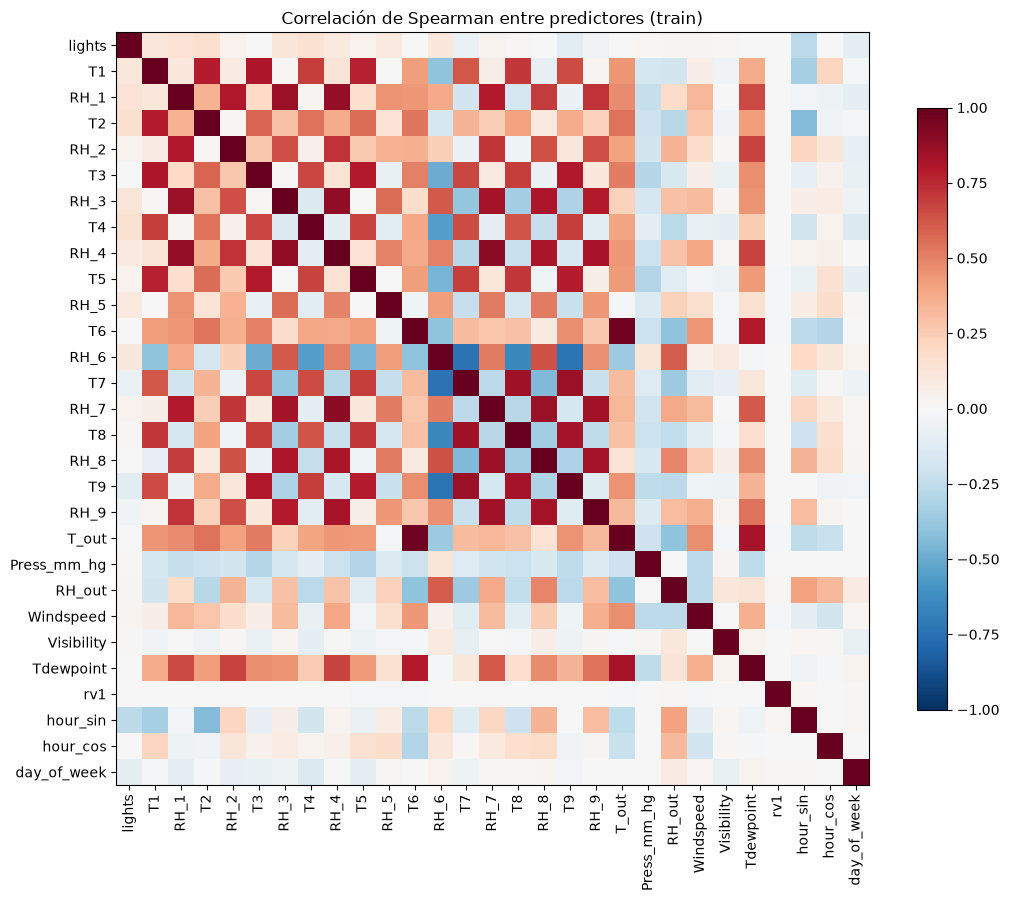

Pares con |rho| >= 0.85: 7


,level_0,level_1,rho
338,T6,T_out,0.976
246,RH_4,RH_7,0.894
182,RH_3,RH_4,0.889
66,RH_1,RH_4,0.879
422,RH_7,RH_8,0.866
394,T7,T9,0.866
64,RH_1,RH_3,0.866


In [9]:
corr = X_train.drop(columns=["rv2"]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, shrink=.8); ax.set_title("Correlación de Spearman entre predictores (train)")
plt.tight_layout(); plt.show()

pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
         .rename("rho").reset_index())
pares = pares.loc[pares["rho"].abs() >= 0.85].sort_values("rho", key=abs, ascending=False)
print(f"Pares con |rho| >= 0.85: {len(pares)}")
display(pares.head(20))

In [10]:
# Agrupamiento jerárquico con distancia 1 - |rho| para ver bloques redundantes
dist = 1 - corr.abs().values
cond = dist[np.triu_indices(len(corr), 1)]
grupos = hierarchy.fcluster(hierarchy.linkage(cond, "average"), t=0.25, criterion="distance")
bloques = pd.Series(corr.columns, index=grupos).groupby(level=0).agg(list)
for b in bloques:
    if len(b) > 1:
        print(b)

['RH_1', 'RH_3', 'RH_4', 'RH_7', 'RH_8', 'RH_9']
['T7', 'T8', 'T9']
['T1', 'T3', 'T5']
['T6', 'T_out', 'Tdewpoint']


Hay **mucha redundancia**: las temperaturas interiores forman un bloque muy correlacionado entre sí (todas suben con la estación y con la calefacción), `T6` (sensor exterior norte) es casi idéntico a `T_out`, y las humedades interiores forman otro bloque. Con tantas variables que cuentan "lo mismo", una RNA puede repartir peso de forma inestable entre ellas.

### 4.3 Comportamiento de `rv1` y `rv2`

¿rv1 == rv2 en todas las filas? True
Correlación Spearman con Appliances (train): -0.0083


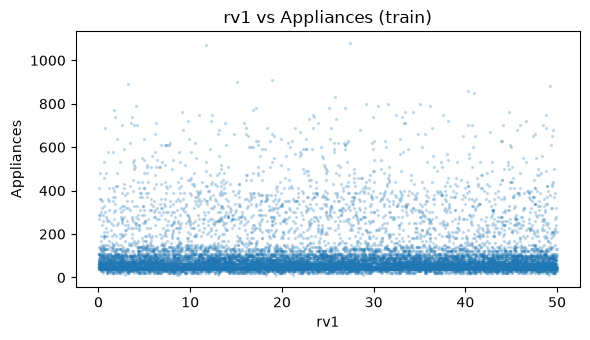

In [11]:
print("¿rv1 == rv2 en todas las filas?", bool((X["rv1"] == X["rv2"]).all()))
print("Correlación Spearman con Appliances (train):",
      round(X_train["rv1"].corr(y_train, method="spearman"), 4))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(X_train["rv1"], y_train, s=2, alpha=.2)
ax.set(xlabel="rv1", ylabel="Appliances", title="rv1 vs Appliances (train)")
plt.tight_layout(); plt.show()

`rv1` y `rv2` son **la misma columna** (duplicado exacto) y no tienen relación con el objetivo: son ruido de control. Cualquier método que les asigne importancia está sobreajustando. Sirven como "termómetro" de la calidad de cada técnica de selección.

### 4.4 Cambio de distribución entre train y validación

Como train es invierno y validación primavera, se mide cuánto se desplaza cada variable, en desvíos estándar de train.

,RH_6,RH_3,T4,RH_2,T9,T5,T3,RH_4,RH_9,T7,...,Press_mm_hg,Windspeed,lights,Visibility,Tdewpoint,hour_cos,hour_sin,day_of_week,rv1,rv2
desplazamiento (σ),-1.574,-1.185,1.168,-1.119,1.048,1.048,1.046,-1.026,-1.019,0.956,...,0.461,-0.33,-0.282,-0.105,0.038,0.016,-0.014,-0.013,-0.008,-0.008


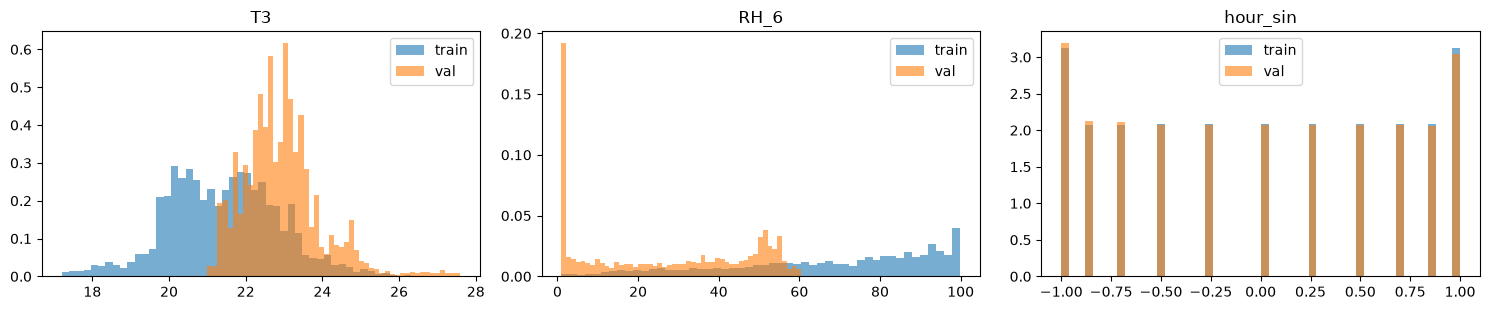

In [12]:
deriva = ((X_val.mean() - X_train.mean()) / X_train.std()).rename("desplazamiento (σ)")
deriva = deriva.sort_values(key=abs, ascending=False)
display(deriva.to_frame().T)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, col in zip(axes, ["T3", "RH_6", "hour_sin"]):
    ax.hist(X_train[col], bins=50, alpha=.6, density=True, label="train")
    ax.hist(X_val[col], bins=50, alpha=.6, density=True, label="val")
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

Casi todos los sensores ambientales se desplazan **cerca de 1 σ o más** entre train y validación (ej. `RH_6`, `T3`, `T4`, `T9`). Las variables de calendario (`hour_*`, `day_of_week`) y `lights` prácticamente no se mueven. Esto anticipa un problema: la red va a tener que **extrapolar** en las variables de sensores, y lo que aprendió en invierno puede no valer en primavera.

## 5. Relevancia de variables (técnicas de selección)

Se calculan cuatro criterios. Los tres primeros usan **solo train**; la importancia por permutación usa el modelo entrenado en train evaluado sobre validación (nunca prueba).

In [13]:
# (a) Información mutua (captura relaciones no lineales)
mi = pd.Series(mutual_info_regression(X_train, y_train, random_state=SEED), index=X.columns)

# (b) Lasso con validación cruzada temporal dentro de train
scaler_l = StandardScaler().fit(X_train)
lasso = LassoCV(cv=TimeSeriesSplit(n_splits=5), random_state=SEED, max_iter=20000)
lasso.fit(scaler_l.transform(X_train), y_train)
coef_lasso = pd.Series(lasso.coef_, index=X.columns)
print(f"Lasso: alpha = {lasso.alpha_:.3f}, variables con coeficiente ≠ 0: {(coef_lasso != 0).sum()}")

Lasso: alpha = 1.886, variables con coeficiente ≠ 0: 15


In [14]:
def rna():
    # Arquitectura fija para todo el experimento (la del código inicial)
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu",
                             max_iter=800, shuffle=False, random_state=SEED)),
    ])

def metricas(y_true, pred):
    return {"MAE": mean_absolute_error(y_true, pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
            "R2": r2_score(y_true, pred)}

todas = list(X.columns)
t0 = time.time()
rna_todas = rna().fit(X_train[todas], y_train)
print(f"RNA con todas ({len(todas)} variables), {time.time() - t0:.0f} s:",
      {k: round(v, 3) for k, v in metricas(y_val, rna_todas.predict(X_val[todas])).items()})

# (c) Importancia por permutación sobre validación
perm = permutation_importance(rna_todas, X_val[todas], y_val, n_repeats=5,
                              random_state=SEED, scoring="neg_mean_absolute_error", n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=todas)

RNA con todas (30 variables), 17 s: {'MAE': 60.759, 'RMSE': np.float64(104.607), 'R2': -0.286}


In [15]:
ranking = pd.DataFrame({
    "spearman_abs": asoc["spearman"].abs(),
    "MI": mi,
    "lasso_coef": coef_lasso.round(2),
    "perm_MAE": imp_perm,
    "deriva_σ": deriva.abs(),
})
ranking["rank_spearman"] = ranking["spearman_abs"].rank(ascending=False)
ranking["rank_MI"] = ranking["MI"].rank(ascending=False)
ranking["rank_lasso"] = ranking["lasso_coef"].abs().rank(ascending=False)
ranking["rank_perm"] = ranking["perm_MAE"].rank(ascending=False)
ranking["rank_medio"] = ranking.filter(like="rank_").mean(axis=1)
ranking = ranking.sort_values("rank_medio")
display(ranking)

,spearman_abs,MI,lasso_coef,perm_MAE,deriva_σ,rank_spearman,rank_MI,rank_lasso,rank_perm,rank_medio
hour_sin,0.431,0.169,-18.47,21.402,0.014,1.0,1.0,3.0,2.0,1.75
hour_cos,0.297,0.109,-24.16,13.004,0.016,4.0,7.0,1.0,3.0,3.75
T3,0.239,0.120,19.05,5.445,1.046,8.0,3.0,2.0,7.0,5.00
T4,0.240,0.116,-3.32,7.037,1.168,7.0,4.0,10.0,5.0,6.50
T9,0.178,0.121,-3.71,4.875,1.048,15.0,2.0,8.0,9.0,8.50
T2,0.325,0.108,-0.00,9.639,0.701,3.0,8.0,23.0,4.0,9.50
T8,0.258,0.115,0.47,3.368,0.766,6.0,5.0,15.0,15.0,10.25
T1,0.265,0.088,-0.00,5.756,0.760,5.0,13.0,23.0,6.0,11.75
RH_7,0.129,0.086,-7.68,4.169,0.837,18.0,14.0,6.0,11.0,12.25
lights,0.354,0.081,17.23,0.527,0.282,2.0,17.0,4.0,28.0,12.75


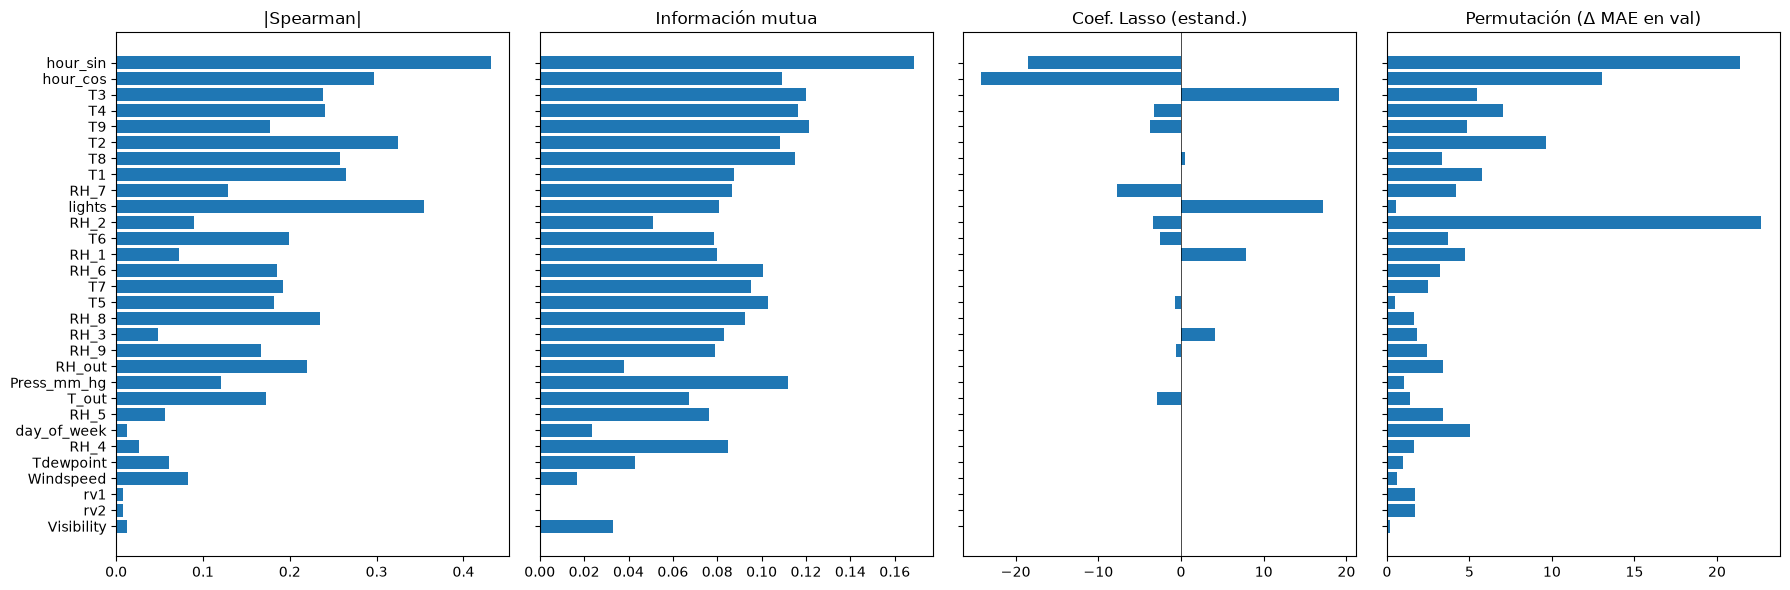

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharey=True)
orden = ranking.index[::-1]
for ax, (col, tit) in zip(axes, [("spearman_abs", "|Spearman|"), ("MI", "Información mutua"),
                                 ("lasso_coef", "Coef. Lasso (estand.)"), ("perm_MAE", "Permutación (Δ MAE en val)")]):
    ax.barh(orden, ranking.loc[orden, col])
    ax.set_title(tit); ax.axvline(0, color="k", lw=.5)
plt.tight_layout(); plt.show()

**Lectura de los rankings**

- Las cuatro técnicas coinciden en que la **hora** (`hour_sin`, `hour_cos`) es lo más informativo.
- La información mutua le da valores altos a muchas temperaturas y a `Press_mm_hg`. Parte de eso es real, pero parte es que, en un período corto, las variables que tienen tendencia estacional "funcionan como calendario": identifican en qué semana estamos.
- Lasso se queda con unas 15 variables y descarta `rv1`/`rv2`, `day_of_week` y la mayoría de las variables meteorológicas; dentro de cada bloque redundante conserva uno o dos representantes.
- La importancia por permutación de la RNA con todas las variables asigna importancia **positiva a `rv1` y `rv2`**: la red aprendió ruido, una señal clara de sobreajuste. También le da mucho peso a variables de humedad (`RH_2`) que se desplazan entre períodos.

## 6. Subconjuntos candidatos

Se proponen cinco subconjuntos, cada uno con un criterio distinto:

In [17]:
def filtrar_redundancia(orden, umbral=0.85, k=None):
    # Recorre el ranking y agrega una variable solo si no está muy correlacionada con las ya elegidas
    corr_abs = X_train.corr(method="spearman").abs()
    sel = []
    for c in orden:
        if all(corr_abs.loc[c, s] < umbral for s in sel):
            sel.append(c)
        if k and len(sel) == k:
            break
    return sel

orden_filtro = (ranking["rank_spearman"] + ranking["rank_MI"]).sort_values().index
orden_filtro = [c for c in orden_filtro if c not in ("rv1", "rv2")]

subconjuntos = {
    "A_todas": todas,
    "B_filtro_corr_MI": filtrar_redundancia(orden_filtro, umbral=0.85, k=10),
    "C_lasso": list(coef_lasso[coef_lasso != 0].index),
    "D_permutacion_top10": list(imp_perm.sort_values(ascending=False).index[:10]),
    "E_estables": ["hour_sin", "hour_cos", "day_of_week", "lights"],
}
for nombre, vars_ in subconjuntos.items():
    print(f"{nombre:22s} ({len(vars_):2d}): {vars_ if nombre != 'A_todas' else '…todas…'}")

A_todas                (30): …todas…
B_filtro_corr_MI       (10): ['hour_sin', 'hour_cos', 'T3', 'T4', 'T2', 'T8', 'T9', 'T1', 'lights', 'RH_8']
C_lasso                (15): ['lights', 'RH_1', 'RH_2', 'T3', 'RH_3', 'T4', 'T5', 'T6', 'RH_7', 'T8', 'T9', 'RH_9', 'T_out', 'hour_sin', 'hour_cos']
D_permutacion_top10    (10): ['RH_2', 'hour_sin', 'hour_cos', 'T2', 'T4', 'T1', 'T3', 'day_of_week', 'T9', 'RH_1']
E_estables             ( 4): ['hour_sin', 'hour_cos', 'day_of_week', 'lights']


- **A — todas**: referencia (30 variables: 27 originales + 3 temporales).
- **B — filtro correlación + IM**: ranking combinado de Spearman e información mutua, eliminando variables con |ρ| ≥ 0.85 respecto de una ya elegida (un representante por bloque redundante) y excluyendo `rv1`/`rv2`.
- **C — Lasso**: variables con coeficiente distinto de cero (regularización L1 con CV temporal dentro de train).
- **D — permutación top‑10**: las 10 más importantes para la propia RNA según permutación en validación (método *wrapper*/dependiente del modelo).
- **E — estables**: solo calendario + `lights`, las variables con relevancia en todos los rankings **y** sin deriva entre períodos. Es una hipótesis derivada de la sección 4.4.

## 7. Comparación con la misma arquitectura

Para cada subconjunto se entrena exactamente la misma RNA y se evalúa en validación. Como las RNA son sensibles a la inicialización, además de la semilla fija (42) se repite con semillas 0, 1 y 2 para medir **estabilidad**. Solo cambia la lista de variables.

In [18]:
def correr(vars_, semilla):
    m = rna()
    m.set_params(mlp__random_state=semilla)
    m.fit(X_train[vars_], y_train)
    return metricas(y_val, m.predict(X_val[vars_]))

semillas = [SEED, 0, 1, 2]
trabajos = [(nombre, s) for nombre in subconjuntos for s in semillas]
t0 = time.time()
salidas = Parallel(n_jobs=-1)(delayed(correr)(subconjuntos[nombre], s) for nombre, s in trabajos)
print(f"{len(trabajos)} entrenamientos en {time.time() - t0:.0f} s")

res = pd.DataFrame([{"subconjunto": nombre, "semilla": s, **m} for (nombre, s), m in zip(trabajos, salidas)])
res["n_vars"] = res["subconjunto"].map(lambda k: len(subconjuntos[k]))

20 entrenamientos en 120 s


In [19]:
print("Validación con semilla 42:")
display(res[res["semilla"] == SEED].set_index("subconjunto")[["n_vars", "MAE", "RMSE", "R2"]])

print("Estabilidad (4 semillas): media ± desvío")
resumen = res.groupby("subconjunto").agg(
    n_vars=("n_vars", "first"),
    MAE_media=("MAE", "mean"), MAE_std=("MAE", "std"),
    RMSE_media=("RMSE", "mean"), RMSE_std=("RMSE", "std"),
    R2_media=("R2", "mean"), R2_std=("R2", "std"),
).sort_values("MAE_media")
display(resumen)

# Referencia ingenua (no es una RNA): predecir siempre la media de train
print("Referencia 'media de train' en val:",
      {k: round(v, 3) for k, v in metricas(y_val, np.full(len(y_val), y_train.mean())).items()})

Validación con semilla 42:


,n_vars,MAE,RMSE,R2
subconjunto,,,,
A_todas,30,60.759,104.607,-0.286
B_filtro_corr_MI,10,49.890,90.089,0.046
C_lasso,15,70.721,109.382,-0.406
D_permutacion_top10,10,66.348,108.462,-0.383
E_estables,4,46.281,87.970,0.090


Estabilidad (4 semillas): media ± desvío


,n_vars,MAE_media,MAE_std,RMSE_media,RMSE_std,R2_media,R2_std
subconjunto,,,,,,,
E_estables,4,46.336,0.314,88.016,0.320,0.089,0.007
B_filtro_corr_MI,10,51.547,1.694,91.488,1.471,0.016,0.032
C_lasso,15,62.037,6.212,103.119,5.557,-0.253,0.134
A_todas,30,62.984,2.719,106.041,3.074,-0.322,0.077
D_permutacion_top10,10,63.286,4.170,103.762,3.834,-0.267,0.094


Referencia 'media de train' en val: {'MAE': 53.968, 'RMSE': np.float64(92.394), 'R2': -0.003}


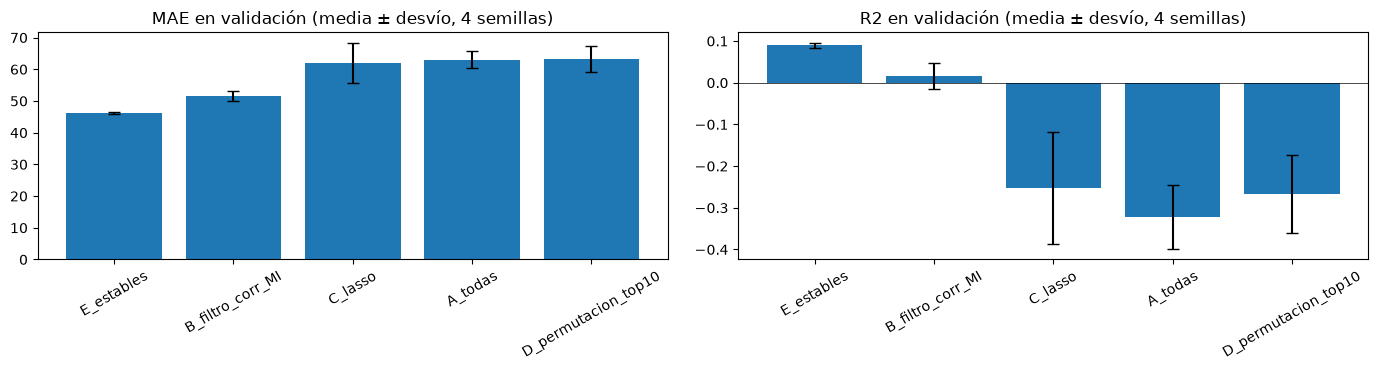

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, met in zip(axes, ["MAE", "R2"]):
    orden = resumen.index
    ax.bar(orden, resumen[f"{met}_media"], yerr=resumen[f"{met}_std"], capsize=4, color="tab:blue")
    ax.set_title(f"{met} en validación (media ± desvío, 4 semillas)")
    ax.tick_params(axis="x", rotation=30); ax.axhline(0, color="k", lw=.5)
plt.tight_layout(); plt.show()

### Discusión de la comparación en validación

- **Con todas las variables la RNA rinde peor que predecir la media** (R² ≈ −0.32 promedio; la media de train da R² ≈ 0 y MAE ≈ 54 Wh). Tener más variables no ayuda: la red se apoya en sensores que en primavera toman valores que no vio en invierno, y además aprende ruido (`rv1`/`rv2` tienen importancia por permutación positiva).
- **Lasso (C) y permutación (D) no mejoran sobre "todas"** y son los **menos estables** (desvío de MAE de 4–6 Wh entre semillas). Los dos eligen muchos sensores con deriva alta: `RH_2`, la variable más importante para D, se desplaza 1.1 σ. La permutación sobre validación mide lo que *esta* red sobreajustada usa, no lo que generaliza.
- **El filtro con eliminación de redundancia (B)** ya mejora mucho (MAE ≈ 51.5 Wh, R² ≈ 0.02) usando 10 variables: un representante por bloque redundante, más la hora y `lights`.
- **El subconjunto E (calendario + `lights`) es el mejor y el más estable**: MAE 46.3 ± 0.3 Wh, R² 0.089 ± 0.007, con solo 4 variables. Es el único que supera claramente a la referencia ingenua en todas las semillas.

**Selección final: E = `hour_sin`, `hour_cos`, `day_of_week`, `lights`**, porque:
1. Da el mejor desempeño medio en validación (−27 % de MAE frente a "todas").
2. Es el más estable entre semillas (desvío 10 veces menor).
3. Usa la menor cantidad de variables, todas con relevancia consistente en los rankings y **sin deriva** entre períodos.

`day_of_week` aporta poco por sí sola (|ρ| ≈ 0.01), pero se mantiene porque no tiene deriva y captura el ritmo semanal, que la RNA puede combinar con la hora.

## 8. Evaluación final en prueba (una única vez)

Con la configuración congelada (arquitectura, semilla 42 y subconjunto final elegido por **menor MAE medio en validación**) se reentrena cada modelo con **train + validación**, respetando el orden temporal, y se evalúa en prueba **una sola vez**. Se reporta también el modelo con todas las variables, entrenado de la misma forma, para la comparación pedida.

In [21]:
# Criterio: menor MAE medio en validación entre semillas (desempate: menos variables)
nombre_final = resumen.sort_values(["MAE_media", "n_vars"]).index[0]
seleccion_final = subconjuntos[nombre_final]
print("Subconjunto final:", nombre_final, seleccion_final)

X_dev, y_dev = X.iloc[:fin_val], y.iloc[:fin_val]
val42 = res[res["semilla"] == SEED].set_index("subconjunto")
filas, preds = {}, {}
for nombre in ["A_todas", nombre_final]:
    vars_ = subconjuntos[nombre]
    m = rna().fit(X_dev[vars_], y_dev)
    preds[nombre] = m.predict(X_test[vars_])
    filas[nombre] = {"n_vars": len(vars_),
                     "MAE_val": val42.loc[nombre, "MAE"], "R2_val": val42.loc[nombre, "R2"],
                     **{f"{k}_test": v for k, v in metricas(y_test, preds[nombre]).items()}}
tabla = pd.DataFrame(filas).T
display(tabla)

Subconjunto final: E_estables ['hour_sin', 'hour_cos', 'day_of_week', 'lights']


,n_vars,MAE_val,R2_val,MAE_test,RMSE_test,R2_test
A_todas,30.0,60.759,-0.286,149.949,195.664,-3.636
E_estables,4.0,46.281,0.090,44.243,83.848,0.149


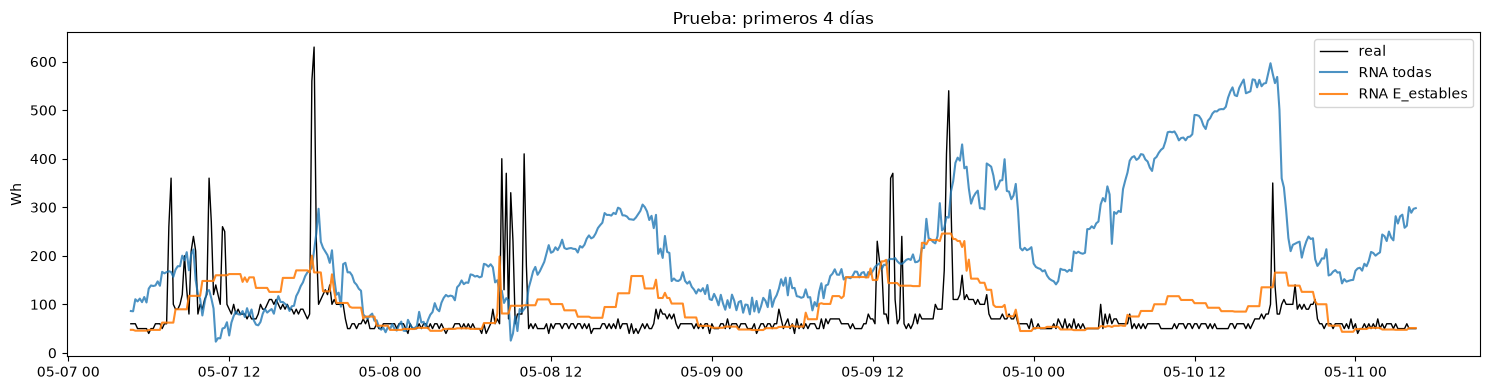

In [22]:
ventana = slice(0, 6 * 24 * 4)  # primeros 4 días de prueba
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(fechas.iloc[fin_val:].iloc[ventana], y_test.iloc[ventana], label="real", color="k", lw=1)
ax.plot(fechas.iloc[fin_val:].iloc[ventana], preds["A_todas"][ventana], label="RNA todas", alpha=.8)
ax.plot(fechas.iloc[fin_val:].iloc[ventana], preds[nombre_final][ventana], label=f"RNA {nombre_final}", alpha=.9)
ax.set(title="Prueba: primeros 4 días", ylabel="Wh"); ax.legend()
plt.tight_layout(); plt.show()

## 9. Conclusiones

**Resultado.** En prueba, la RNA con las 4 variables seleccionadas obtiene **MAE ≈ 44 Wh, RMSE ≈ 84 Wh y R² ≈ 0.15**, mientras que la misma arquitectura con las 30 variables **colapsa** (MAE ≈ 150 Wh, R² ≈ −3.6). La brecha es mayor que en validación porque la prueba (mayo) está todavía más lejos del invierno de entrenamiento y las temperaturas y humedades se alejan aún más del rango que conoció la red. Esto confirma que el problema principal del modelo con todas las variables es la **extrapolación ante deriva**, no la falta de información.

**Estabilidad.** La selección final es estable en dos sentidos: entre semillas de la RNA (σ(MAE) ≈ 0.3 Wh) y entre períodos (las variables elegidas no se desplazan entre train, validación y prueba). Los subconjuntos basados en sensores cambian mucho según la semilla y según el método que los elige.

**Redundancia.** Los sensores interiores forman bloques casi colineales (temperaturas entre sí, `T6` ≈ `T_out`, humedades entre sí). Elegir variables "por ranking individual" (top‑k de MI) trae el bloque entero; filtrar redundancia (subconjunto B) fue lo que más ayudó entre los métodos automáticos.

**Posibles fugas y cuidados.**
- **Partición y escalado**: la partición es cronológica, el `StandardScaler` va dentro del `Pipeline` (se ajusta solo con train) y el MLP usa `shuffle=False`. Rankings y Lasso se calcularon solo con train, y la prueba se usó una única vez.
- **`rv1`/`rv2`**: son ruido y además duplicados. Ningún subconjunto final los incluye, pero la permutación les asignó importancia: un aviso sobre el uso ciego de métodos *wrapper*.
- **`lights`** se mide en el **mismo intervalo** que `Appliances`. Si el objetivo fuera *pronosticar* el consumo de los próximos 10 minutos, `lights` no estaría disponible a tiempo y sería una fuga temporal; habría que usar su valor rezagado (t−1). En el planteo de la consigna (estimar el consumo a partir de mediciones simultáneas) es válido, pero conviene dejarlo explícito.
- Las variables con tendencia estacional pueden funcionar como un "reloj" del período de entrenamiento. Eso explica parte de su información mutua alta y por qué no generalizan.

**Limitaciones.** Un R² de 0.15 sigue siendo bajo: los picos de consumo son eventos discretos que ni la hora ni el clima explican bien. Mejoras posibles, manteniendo el criterio de comparar solo el conjunto de variables: agregar rezagos del propio consumo (t−1, t−6), transformar el objetivo con `log1p` por la asimetría, o usar variables relativas al período (diferencias interior−exterior) que derivan menos que los niveles absolutos.